# XAUUSD D1 — Baseline Regime Detection & N-Method Performance

This notebook evaluates whether a simple, interpretable market-regime classifier helps explain the performance of three N-Method strategy variants.

## Research workflow

1. Classify each XAUUSD daily candle as **Bullish**, **Bearish**, **Sideways**, or **Unclassified** using EMA(50), EMA(200), and ADX(14).
2. Measure Bullish N, Bearish N, and Ranging N performance within each detected regime.
3. Compare the original unfiltered results with a pre-defined matched-regime filter:
   - Bullish N trades only in Bullish regimes.
   - Bearish N trades only in Bearish regimes.
   - Ranging N trades only in Sideways regimes.

The N-Method trade list is generated by `01_N_Method_Backtest.ipynb`. Run that notebook first to refresh the trade-level output in `outputs/`.

**Baseline, not an optimized model:** EMA/ADX settings and the matched-regime mapping are fixed as a simple benchmark. They are not claimed to be universally optimal.


## 1. Baseline regime definition

We use a transparent, rule-based classifier built from two commonly used indicators: **EMA(50) / EMA(200) + ADX(14)**.

| Regime | Rule |
|---|---|
| Bullish | ADX(14) ≥ 20 and EMA(50) > EMA(200) |
| Bearish | ADX(14) ≥ 20 and EMA(50) < EMA(200) |
| Sideways | ADX(14) < 20 |
| Unclassified | Required indicator values are not yet available |

EMA alignment defines directional bias; ADX estimates trend strength. ADX itself does not indicate direction. The 20 threshold and 50/200 EMA periods are fixed baseline choices, not parameters optimized on this dataset. Indicators are calculated using data available through the close of the bar being classified.

### Timing and look-ahead control

Each trade is assigned the regime on its `signal_date`—the date on which the N-Method setup is confirmed. The pending entry order becomes active on the following daily candle. This avoids assigning a regime observed only after the setup was formed or after the trade was entered.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "XAUUSD_D1.csv"
TRADES_PATH = PROJECT_ROOT / "outputs" / "XAUUSD_D1_N_method_trades.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Source data not found: {DATA_PATH}. See data/README.md.")
if not TRADES_PATH.exists():
    raise FileNotFoundError(
        f"N-Method trades not found: {TRADES_PATH}. Run notebooks/01_N_Method_Backtest.ipynb first."
    )

# The supplied historical CSV has no header row: Date, Open, High, Low, Close, [Volume].
raw = pd.read_csv(DATA_PATH, header=None)
if raw.shape[1] < 5:
    raise ValueError("CSV must contain at least Date, Open, High, Low, and Close columns.")
cols = ["Date", "Open", "High", "Low", "Close"] + (["Volume"] if raw.shape[1] >= 6 else [])
raw = raw.iloc[:, :len(cols)].copy()
raw.columns = cols
raw["Date"] = pd.to_datetime(raw["Date"], errors="coerce")
for col in ["Open", "High", "Low", "Close"]:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")
data = (raw.dropna(subset=["Date", "Open", "High", "Low", "Close"])
            .sort_values("Date").drop_duplicates("Date").set_index("Date"))

invalid = (data["High"] < data[["Open", "Close", "Low"]].max(axis=1)) | (
    data["Low"] > data[["Open", "Close", "High"]].min(axis=1)
)
if invalid.any():
    raise ValueError(f"Found {invalid.sum()} invalid OHLC bars.")

print(f"Data: {len(data):,} daily bars | {data.index.min().date()} to {data.index.max().date()}")
print(f"Trade file: {TRADES_PATH.relative_to(PROJECT_ROOT)}")
display(data.head())


Data: 5,221 daily bars | 2010-02-01 to 2026-11-11
Trade file: outputs/XAUUSD_D1_N_method_trades.csv


,Open,High,Low,Close,Volume
Date,,,,,
2010-02-01,1078.887,1107.084,1076.047,1103.854,1237
2010-02-02,1103.766,1117.679,1098.554,1114.676,1418
2010-02-03,1115.115,1124.254,1106.783,1108.657,1418
2010-02-04,1108.507,1110.442,1059.334,1064.238,1422
2010-02-05,1064.293,1068.206,1044.703,1065.619,1315


In [2]:
# Calculate EMA(50), EMA(200), and ADX(14) using data available at each daily close.
data["EMA50"] = data["Close"].ewm(span=50, adjust=False, min_periods=50).mean()
data["EMA200"] = data["Close"].ewm(span=200, adjust=False, min_periods=200).mean()

# Wilder-style smoothing, implemented with exponential weights alpha = 1 / period.
period = 14
prev_close = data["Close"].shift(1)
true_range = pd.concat([
    data["High"] - data["Low"],
    (data["High"] - prev_close).abs(),
    (data["Low"] - prev_close).abs(),
], axis=1).max(axis=1)
up_move = data["High"].diff()
down_move = -data["Low"].diff()
plus_dm = pd.Series(np.where((up_move > down_move) & (up_move > 0), up_move, 0.0), index=data.index)
minus_dm = pd.Series(np.where((down_move > up_move) & (down_move > 0), down_move, 0.0), index=data.index)

smoothed_tr = true_range.ewm(alpha=1/period, adjust=False, min_periods=period).mean()
smoothed_plus_dm = plus_dm.ewm(alpha=1/period, adjust=False, min_periods=period).mean()
smoothed_minus_dm = minus_dm.ewm(alpha=1/period, adjust=False, min_periods=period).mean()
data["+DI14"] = 100 * smoothed_plus_dm / smoothed_tr
data["-DI14"] = 100 * smoothed_minus_dm / smoothed_tr
dx = 100 * (data["+DI14"] - data["-DI14"]).abs() / (data["+DI14"] + data["-DI14"])
data["ADX14"] = dx.ewm(alpha=1/period, adjust=False, min_periods=period).mean()

conditions = [
    data["ADX14"] < 20,
    (data["ADX14"] >= 20) & (data["EMA50"] > data["EMA200"]),
    (data["ADX14"] >= 20) & (data["EMA50"] < data["EMA200"]),
]
data["Regime"] = np.select(conditions, ["Sideways", "Bullish", "Bearish"], default="Unclassified")

regime_order = ["Bullish", "Bearish", "Sideways", "Unclassified"]
regime_distribution = (data["Regime"].value_counts()
                       .reindex(regime_order, fill_value=0)
                       .rename("Bars").to_frame())
regime_distribution["Share %"] = 100 * regime_distribution["Bars"] / len(data)
display(regime_distribution.round(2))


,Bars,Share %
Regime,,
Bullish,2099,40.20
Bearish,1255,24.04
Sideways,1771,33.92
Unclassified,96,1.84


## 2. Join detected regimes to N-Method trades

We use the trade list generated by the previous notebook. Trades marked `AMBIGUOUS_BOTH_SIDES` are excluded from performance statistics, consistent with the original backtest summary. `OPEN_AT_END` trades remain included using their mark-to-market R value at the final available candle; they are not closed-trade results.


In [3]:
trades = pd.read_csv(TRADES_PATH)
for col in ["signal_date", "entry_date", "exit_date"]:
    trades[col] = pd.to_datetime(trades[col])

# Attach the regime known at setup confirmation (signal_date), not at a later date.
regime_at_signal = data[["Regime"]].copy()
trades = trades.drop(columns=["Regime"], errors="ignore").merge(
    regime_at_signal, left_on="signal_date", right_index=True, how="left"
)
valid = trades[trades["result"].isin(["TP", "SL", "OPEN_AT_END"])].copy()
ambiguous_count = int((trades["result"] == "AMBIGUOUS_BOTH_SIDES").sum())
print(f"Valid trades included: {len(valid)} | Ambiguous trades excluded: {ambiguous_count}")
display(valid.head())


Valid trades included: 146 | Ambiguous trades excluded: 0


,setup,side,signal_date,entry_date,entry,sl,tp,exit_date,exit,result,R,bars_held,pattern,Regime
0,bearish,short,2010-03-21,2010-03-22,1097.594182,1133.129818,1026.522911,2010-04-06,1133.129818,SL,-1.0,14,P1=1144.59; P2=1098.29; P3=1132.43,Sideways
1,bullish,long,2010-03-16,2010-04-07,1145.316036,1097.565964,1240.816179,2010-05-12,1240.816179,TP,2.0,31,P1=1088.04; P2=1144.59; P3=1098.29,Sideways
2,bullish,long,2010-05-25,2010-06-08,1249.824550,1165.407450,1418.658750,2010-07-27,1165.407450,SL,-1.0,43,P1=1157.51; P2=1248.76; P3=1166.48,Unclassified
3,bearish,short,2010-07-01,2010-07-02,1200.897000,1263.127671,1076.435657,2010-09-14,1263.127671,SL,-1.0,64,P1=1264.29; P2=1223.81; P3=1262.18,Sideways
4,bullish,long,2010-08-13,2010-08-15,1215.013000,1189.838746,1265.361507,2010-09-14,1265.361507,TP,2.0,27,P1=1156.93; P2=1210.46; P3=1190.44,Unclassified


In [4]:
def performance_stats(group):
    group = group[group["result"].isin(["TP", "SL", "OPEN_AT_END"])]
    if group.empty:
        return pd.Series({"Trades": 0, "Win rate %": np.nan, "Net R": 0.0,
                          "Profit factor (R)": np.nan, "Avg R": np.nan})
    gross_profit = group.loc[group["R"] > 0, "R"].sum()
    gross_loss = -group.loc[group["R"] < 0, "R"].sum()
    return pd.Series({
        "Trades": len(group),
        "Win rate %": 100 * (group["R"] > 0).mean(),
        "Net R": group["R"].sum(),
        "Profit factor (R)": gross_profit / gross_loss if gross_loss > 0 else np.inf,
        "Avg R": group["R"].mean(),
    })

strategies = ["bullish", "bearish", "ranging"]
regimes = ["Bullish", "Bearish", "Sideways", "Unclassified"]
rows = []
for strategy in strategies:
    for regime in regimes:
        subset = valid[(valid["setup"] == strategy) & (valid["Regime"] == regime)]
        stats = performance_stats(subset).to_dict()
        rows.append({"Strategy": strategy.title() + " N", "Regime": regime, **stats})

regime_performance = pd.DataFrame(rows)
display(regime_performance.round(3))


,Strategy,Regime,Trades,Win rate %,Net R,Profit factor (R),Avg R
0,Bullish N,Bullish,30.0,33.333,0.000,1.000,0.000
1,Bullish N,Bearish,16.0,37.500,1.873,1.185,0.117
2,Bullish N,Sideways,26.0,53.846,16.000,2.333,0.615
3,Bullish N,Unclassified,2.0,50.000,1.000,2.000,0.500
4,Bearish N,Bullish,20.0,30.000,-3.077,0.780,-0.154
5,Bearish N,Bearish,13.0,30.769,-1.000,0.889,-0.077
6,Bearish N,Sideways,23.0,26.087,-6.368,0.653,-0.277
7,Bearish N,Unclassified,0.0,NaN,0.000,NaN,NaN
8,Ranging N,Bullish,4.0,50.000,2.003,2.002,0.501
9,Ranging N,Bearish,3.0,33.333,-1.974,0.013,-0.658


## 3. Compare the unfiltered baseline with a matched-regime filter

To avoid choosing the regime mapping after inspecting the results, we define a simple matched-regime rule in advance:

- **Bullish N:** retain trades signaled in Bullish regimes only.
- **Bearish N:** retain trades signaled in Bearish regimes only.
- **Ranging N:** retain trades signaled in Sideways regimes only.

This is a benchmark filter, not a claim that the mapping is optimal. The primary comparison is each strategy's performance with no regime filter versus performance after applying its matched-regime condition.


In [5]:
matched_regime = {"bullish": "Bullish", "bearish": "Bearish", "ranging": "Sideways"}
comparison_rows = []
for strategy in strategies:
    original = valid[valid["setup"] == strategy]
    filtered = valid[(valid["setup"] == strategy) & (valid["Regime"] == matched_regime[strategy])]
    comparison_rows.append({"Strategy": strategy.title() + " N", "Selection": "No regime filter", **performance_stats(original).to_dict()})
    comparison_rows.append({"Strategy": strategy.title() + " N", "Selection": f"Matched regime only ({matched_regime[strategy]})", **performance_stats(filtered).to_dict()})

matched_all = pd.concat([
    valid[(valid["setup"] == strategy) & (valid["Regime"] == regime)]
    for strategy, regime in matched_regime.items()
], ignore_index=True)
comparison_rows.append({"Strategy": "All strategies", "Selection": "No regime filter", **performance_stats(valid).to_dict()})
comparison_rows.append({"Strategy": "All strategies", "Selection": "Matched regime only", **performance_stats(matched_all).to_dict()})
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(3))


,Strategy,Selection,Trades,Win rate %,Net R,Profit factor (R),Avg R
0,Bullish N,No regime filter,74.0,41.892,18.873,1.438,0.255
1,Bullish N,Matched regime only (Bullish),30.0,33.333,0.000,1.000,0.000
2,Bearish N,No regime filter,56.0,28.571,-10.444,0.748,-0.187
3,Bearish N,Matched regime only (Bearish),13.0,30.769,-1.000,0.889,-0.077
4,Ranging N,No regime filter,16.0,37.500,0.029,1.003,0.002
5,Ranging N,Matched regime only (Sideways),9.0,33.333,0.000,1.000,0.000
6,All strategies,No regime filter,146.0,36.301,8.458,1.090,0.058
7,All strategies,Matched regime only,52.0,32.692,-1.000,0.971,-0.019


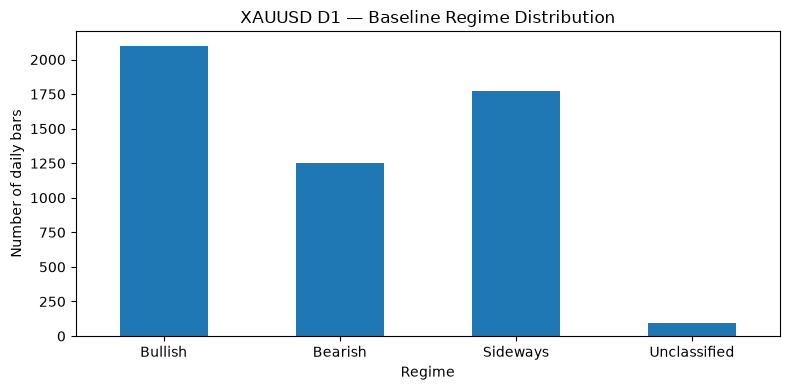

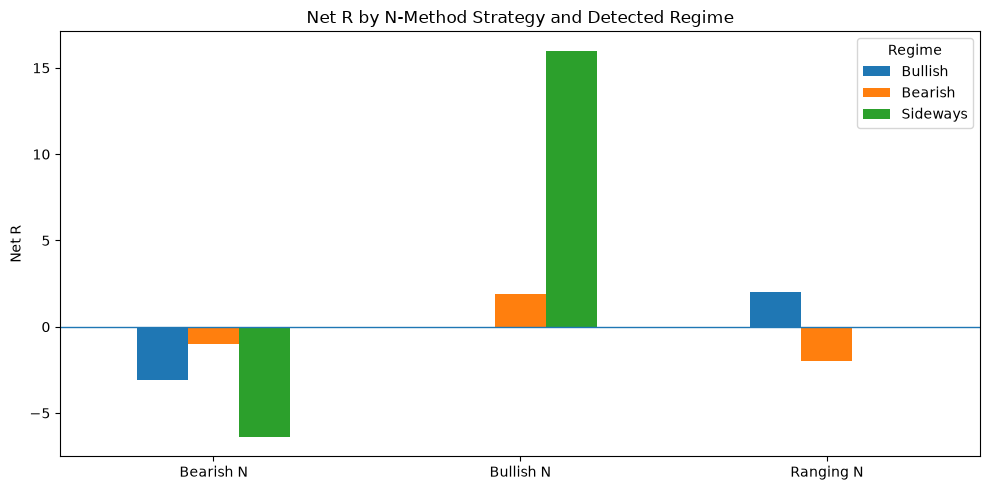

In [6]:
# Visualize regime distribution and conditional strategy results
ax = regime_distribution["Bars"].plot(kind="bar", figsize=(8, 4))
ax.set_title("XAUUSD D1 — Baseline Regime Distribution")
ax.set_xlabel("Regime")
ax.set_ylabel("Number of daily bars")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

pivot_net_r = regime_performance.pivot(index="Strategy", columns="Regime", values="Net R")
ax = pivot_net_r[["Bullish", "Bearish", "Sideways"]].plot(kind="bar", figsize=(10, 5))
ax.axhline(0, linewidth=1)
ax.set_title("Net R by N-Method Strategy and Detected Regime")
ax.set_xlabel("")
ax.set_ylabel("Net R")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [7]:
# Export tables and trade-level labels for downstream analysis
regime_distribution.to_csv(OUTPUT_DIR / "XAUUSD_D1_regime_distribution.csv")
regime_performance.to_csv(OUTPUT_DIR / "XAUUSD_D1_regime_performance.csv", index=False)
comparison.to_csv(OUTPUT_DIR / "XAUUSD_D1_regime_filter_vs_baseline.csv", index=False)
trades.to_csv(OUTPUT_DIR / "XAUUSD_D1_N_method_trades_with_regime.csv", index=False)

print("Exported analysis files to outputs/:")
for filename in [
    "XAUUSD_D1_regime_distribution.csv",
    "XAUUSD_D1_regime_performance.csv",
    "XAUUSD_D1_regime_filter_vs_baseline.csv",
    "XAUUSD_D1_N_method_trades_with_regime.csv",
]:
    print(f"- {filename}")


Exported analysis files to outputs/:
- XAUUSD_D1_regime_distribution.csv
- XAUUSD_D1_regime_performance.csv
- XAUUSD_D1_regime_filter_vs_baseline.csv
- XAUUSD_D1_N_method_trades_with_regime.csv


## 4. Interpretation, limitations, and next research steps

1. **Lagging classification:** EMA and ADX are lagging indicators. A regime label may change after the underlying market transition has already begun.
2. **Conditional, not causal:** performance within a regime describes an observed historical association; it does not show that the regime caused the outcome.
3. **Small subgroups:** some strategy/regime combinations contain very few trades. High win rates or profit factors from tiny samples are unstable.
4. **Signal-time assignment:** regime is sampled on `signal_date`, when the setup is confirmed and before the pending order becomes active.
5. **Open trades:** `OPEN_AT_END` positions use mark-to-market R at the final data point and should not be interpreted as realized closed-trade performance.
6. **Trading costs:** spread, commission, swap, and realistic slippage are not included in the results.
7. **Portfolio overlap:** each strategy is backtested separately. Aggregating trades across strategies assumes each trade risks 1R independently and does not enforce shared capital, concurrent exposure, or portfolio-level risk limits.
8. **No in-sample optimization claim:** do not tune EMA periods, the ADX threshold, or regime mapping on the full history and report the same sample as independent validation.

### Preliminary takeaway

The matched-regime filter does **not** improve the aggregate historical results in this sample. The strongest conditional result is Bullish N during Sideways regimes, but this is an exploratory finding (26 trades) and may be sample-specific. The next step should be a chronological out-of-sample or walk-forward test, with transaction costs and overlap-aware portfolio constraints.
